---

# Tugas Besar 2 IF3170 Inteligensi Artifisial: Logistic Regression

*Notebook bagian Logistic Regression (from scratch) untuk prediksi pembatalan pesanan Ronaldo Hotel. Struktur mengikuti templat notebook tugas besar.*

---

## Kelompok G04: TreeIsAllYouNeed

- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)

---

## Daftar Isi

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

*Ronaldo Hotel membutuhkan sistem klasifikasi untuk mengestimasi pesanan yang akan dibatalkan, memakai pembelajaran mesin klasik tanpa sumber daya komputasi sebesar deep learning.*

## Aim

*Notebook ini membangun Logistic Regression from scratch dengan regularisasi L1, L2, dan Elastic Net, memvalidasinya, membandingkannya dengan `scikit-learn`, lalu menghasilkan submisi Kaggle yang reproducible.*

## Metric

***Macro F1-score** adalah metrik kompetisi, yaitu rata-rata F1 kelas batal dan kelas tidak batal. ROC-AUC dan accuracy dilaporkan sebagai pelengkap.*

$$\text{Macro F1} = \frac{F_1^{(0)} + F_1^{(1)}}{2}, \qquad F_1^{(c)} = \frac{2 \cdot \text{Precision}^{(c)} \cdot \text{Recall}^{(c)}}{\text{Precision}^{(c)} + \text{Recall}^{(c)}}$$

## Dataset

*`train.csv` berisi 27.373 pesanan dengan target `is_canceled` (1 = batal), dan `test.csv` berisi 6.844 pesanan tanpa target. Terdapat 17 fitur: 14 numerik (hitungan, lead time, tarif, tanggal, biner) dan 3 kategorikal (`meal_package`, `room_category`, `booking_channel`). Sebagian nilai kosong pada kedua berkas. Analisis lengkap ada di `eda.ipynb`.*

## Approach

*Model: $P(y=1 \mid x) = \sigma(w \cdot x + b)$ dengan $\sigma(z) = 1/(1+e^{-z})$ [15][16]. Bobot dicari dengan Maximum Likelihood, yaitu meminimumkan log-loss (setara memaksimumkan log conditional likelihood) ditambah penalti regularisasi, memakai mini-batch stochastic gradient descent [16].*

*Implementasi model ada di `src/algoritma/lr/lr.py` dan preprocessing di `src/kaggle/preprocessing.py`. Fungsi bantu (metrik, split, validasi silang) diambil dari `src/kaggle/lr_submission.py` agar notebook dan skrip menghasilkan submisi yang sama.*

---

# Initialization <a name="2"></a>

---

Bagian ini menyiapkan environment, pengaturan, dan berkas data.

## Environment Setup

Baris instalasi dikomentari secara bawaan.

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn

## Import Libraries

Seluruh import notebook diletakkan di sel ini. `scikit-learn` hanya dipakai sebagai pembanding.

In [2]:
import os
import random
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path('..').resolve()))   # folder src, untuk algoritma.lr.lr

from algoritma.lr.lr import LogisticRegression
from preprocessing import (BIN_COLS, CAT_COLS, CONT_COLS, COUNT_COLS, DATE_COLS, FEATURES,
                           ID_COL, TARGET, Preprocessor, drop_duplicates, load_data)
from lr_submission import (GRID, THRESHOLDS, TRAIN_KW, best_threshold, cfg_from_row,
                           compare_sklearn, cross_validate, macro_f1, name_of, report,
                           sklearn_model, stratified_holdout)

## Settings

Path dan konstanta bersama disimpan di kelas ini.

In [3]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('dataset')
    OUTPUT_DIR = Path('../../output/lr')   # folder khusus LR agar tidak bentrok dengan algoritma lain
    HOLDOUT    = 0.2

    NEG_COLOR  = '#2a78d6'   # warna yang sama dengan eda.ipynb
    POS_COLOR  = '#eb6834'
    MUTED      = '#52514e'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert CFG.SEED == TRAIN_KW['seed'], 'seed notebook dan skrip harus sama'
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## Seed Everything

Seed tetap menjaga hasil reproducible. Model from scratch juga memakai `np.random.default_rng(seed)` sendiri.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

Kolom `id` dibaca sebagai teks karena sebagian nilainya mirip angka.

In [5]:
train_df, test_df = load_data(CFG.DATA_DIR)
print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Ringkasan singkat. Analisis lengkap (distribusi, pola waktu, uji kekosongan, drift) ada di `eda.ipynb`.

## Describe Data

In [6]:
pd.DataFrame({
    'dtype': train_df[FEATURES].dtypes.astype(str),
    'n_unique': train_df[FEATURES].nunique(),
    'missing_train_%': (train_df[FEATURES].isna().mean() * 100).round(2),
    'missing_test_%': (test_df[FEATURES].isna().mean() * 100).round(2),
})

,dtype,n_unique,missing_train_%,missing_test_%
num_adults,float64,5,2.96,2.63
num_children,float64,6,11.09,10.91
weekend_nights,int64,8,0.00,0.00
weekday_nights,int64,18,0.00,0.00
prior_cancellations,int64,9,0.00,0.00
prior_completed_bookings,int64,52,0.00,0.00
special_requests,float64,6,9.13,8.66
days_before_arrival,float64,407,4.10,4.24
nightly_rate_idr,float64,2787,7.45,7.89
needs_parking,float64,2,3.95,3.61


## Explore Data

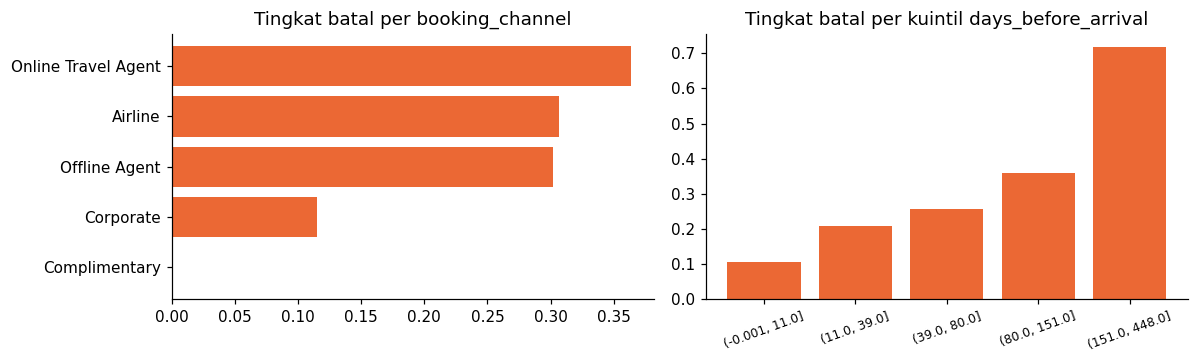

In [7]:
rate = train_df.groupby('booking_channel')[TARGET].agg(['size', 'mean']).sort_values('mean')
lead = train_df.groupby(pd.qcut(train_df['days_before_arrival'], 5), observed=True)[TARGET].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].barh(rate.index, rate['mean'], color=CFG.POS_COLOR)
axes[0].set_title('Tingkat batal per booking_channel')
axes[1].bar(range(len(lead)), lead.values, color=CFG.POS_COLOR)
axes[1].set_xticks(range(len(lead)), [str(i) for i in lead.index], rotation=20, fontsize=8)
axes[1].set_title('Tingkat batal per kuintil days_before_arrival')
plt.tight_layout(); plt.show()

## Verify Data Quality

In [8]:
print('Duplikat penuh (di luar id) di train:', train_df.duplicated(subset=FEATURES + [TARGET]).sum())
print('Baris lengkap di train:', f"{train_df[FEATURES].notna().all(axis=1).mean():.1%}")
print('id unik:', train_df[ID_COL].is_unique and test_df[ID_COL].is_unique,
      '| id train & test beririsan:', bool(set(train_df[ID_COL]) & set(test_df[ID_COL])))

Duplikat penuh (di luar id) di train: 64
Baris lengkap di train: 60.8%
id unik: True | id train & test beririsan: False


#### Insights

> Train memuat 64 duplikat penuh di luar `id` dan hanya 60,8% baris yang lengkap, sehingga imputasi wajib (menghapus baris akan membuang 39,2% data dan tidak mungkin dilakukan pada test). Persentase nilai kosong train dan test hampir sama untuk setiap kolom, `id` unik, dan tidak ada `id` yang beririsan.

---

# Training and Validation Split <a name="4"></a>

---

Split dilakukan sebelum data preparation sehingga data validasi tetap tidak terlihat. Hanya `train.csv` yang di-split; `test.csv` hanya dipakai untuk submisi Kaggle.

Duplikat penuh dibuang **sebelum** split agar baris yang identik tidak muncul di latih dan validasi sekaligus (kebocoran). Split 80/20 bersifat berstrata terhadap target.

In [9]:
train_clean = drop_duplicates(train_df)
y_all = train_clean[TARGET].to_numpy(int)

fit_idx, val_idx = stratified_holdout(y_all, CFG.HOLDOUT, CFG.SEED)
train_set, val_set = train_clean.iloc[fit_idx], train_clean.iloc[val_idx]
y_train, y_val = y_all[fit_idx], y_all[val_idx]

print(f'Duplikat dibuang: {len(train_df) - len(train_clean)}')
print(f'train_set {train_set.shape}  batal {y_train.mean():.2%}')
print(f'val_set   {val_set.shape}  batal {y_val.mean():.2%}')

Duplikat dibuang: 64
train_set (21847, 19)  batal 32.75%
val_set   (5462, 19)  batal 32.75%


---

# Data Preparation <a name="5"></a>

---

Setiap langkah di bawah diimplementasikan di kelas `Preprocessor` (`preprocessing.py`, pandas + NumPy). Sel-sel di bagian ini menampilkan bukti untuk tiap keputusan, **hanya memakai `train_set`**. Statistik (median, kategori, mean/std) dipelajari dari data latih lalu diterapkan ke validasi dan test.

## Select Data

Seluruh 17 fitur dipakai; `id` tidak dipakai sebagai fitur. Fitur yang lemah secara univariat (mis. `room_category`) tidak dibuang karena regularisasi dapat mengecilkan bobotnya.

In [10]:
print(len(FEATURES), 'fitur:', FEATURES)

17 fitur: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'prior_cancellations', 'prior_completed_bookings', 'special_requests', 'days_before_arrival', 'nightly_rate_idr', 'needs_parking', 'is_returning_guest', 'arrival_year', 'arrival_month', 'arrival_day', 'meal_package', 'room_category', 'booking_channel']


## Clean Data

### Missing Values

Tingkat batal saat kosong dibandingkan dengan saat terisi untuk tiap kolom.

In [11]:
rows = []
for col in FEATURES:
    miss = train_set[col].isna()
    if miss.any():
        rows.append({'kolom': col, 'n_kosong': int(miss.sum()),
                     'batal_saat_kosong': y_train[miss.to_numpy()].mean(),
                     'batal_saat_terisi': y_train[~miss.to_numpy()].mean()})
pd.DataFrame(rows).set_index('kolom').round(3)

,n_kosong,batal_saat_kosong,batal_saat_terisi
kolom,,,
num_adults,651,0.323,0.328
num_children,2446,0.334,0.327
special_requests,2037,0.403,0.320
days_before_arrival,875,0.311,0.328
nightly_rate_idr,1560,0.303,0.329
needs_parking,851,0.303,0.328
meal_package,1381,0.326,0.328
room_category,788,0.339,0.327


#### Insights

> Hanya `special_requests` yang tingkat batalnya berbeda jelas saat kosong (40,3% terhadap 32,0%), sehingga kolom ini diimputasi 0 (nilai yang paling mungkin menurut `eda.ipynb`) dan diberi penanda `special_requests_missing`. Kolom numerik lain diimputasi median train. `nightly_rate_idr` diimputasi median per `booking_channel`, karena median kanal Complimentary adalah 0 sedangkan median global sekitar 1,6 juta. Nilai kosong kategorikal menjadi kategori `kosong`.

### Duplicates

In [12]:
print('Duplikat dibuang dari train:', len(train_df) - len(train_clean))
print('Duplikat di test (tidak disentuh):', test_df.duplicated(subset=FEATURES).sum())

Duplikat dibuang dari train: 64
Duplikat di test (tidak disentuh): 3


#### Insights

> 64 duplikat dibuang dari train sebelum split, agar baris identik tidak berada di latih dan validasi sekaligus. Test tidak disentuh (3 baris duplikat tetap ada), karena setiap baris test harus diprediksi.

### Outliers

In [13]:
for col, upper in Preprocessor().clip_upper.items():
    print(f'{col:<18} > {upper:>9,}: train_set {int((train_set[col] > upper).sum())} baris, '
          f'test {int((test_df[col] > upper).sum())} baris')
print('Maks prior_cancellations:', train_set['prior_cancellations'].max(),
      '| maks prior_completed_bookings:', train_set['prior_completed_bookings'].max(),
      '| skew:', train_set[['prior_cancellations', 'prior_completed_bookings']].skew().round(1).tolist())

num_children       >         8: train_set 3 baris, test 0 baris
nightly_rate_idr   > 6,000,000: train_set 3 baris, test 0 baris
Maks prior_cancellations: 13 | maks prior_completed_bookings: 58 | skew: [25.5, 19.2]


#### Insights

> Hanya `num_children > 8` dan `nightly_rate_idr > 6 juta` yang dipangkas (masing-masing 3 baris di `train_set`, tidak ada di test). Nilai aneh lain dipertahankan karena informatif menurut `eda.ipynb` (mis. tarif 0 hampir tidak pernah batal). `prior_cancellations` dan `prior_completed_bookings` sangat miring (skew 25,5 dan 19,2), sehingga ditransformasi `log1p` sebelum standardisasi agar beberapa nilai besar tidak mendominasi gradien.

### Data Errors

In [14]:
dates = pd.to_datetime({'year': train_set['arrival_year'], 'month': train_set['arrival_month'],
                        'day': train_set['arrival_day']}, errors='coerce')
num = COUNT_COLS + CONT_COLS
print('Tanggal tidak valid:', int(dates.isna().sum()))
print('Nilai negatif:', int((train_set[num] < 0).sum().sum()))
no_adult = train_set['num_adults'].eq(0)
print('num_adults = 0:', int(no_adult.sum()), '| di antaranya punya anak:',
      int((no_adult & train_set['num_children'].gt(0)).sum()))
print('Label kategori:', {c: sorted(train_set[c].dropna().unique()) for c in CAT_COLS})

Tanggal tidak valid: 0
Nilai negatif: 0
num_adults = 0: 88 | di antaranya punya anak: 87
Label kategori: {'meal_package': ['Breakfast', 'Full Board', 'Half Board', 'Room Only'], 'room_category': ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G'], 'booking_channel': ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']}


#### Insights

> Tidak ada tanggal tidak valid, nilai negatif, atau label kategori yang tidak konsisten. `num_adults = 0` (88 baris) bukan kesalahan: 87 baris memiliki anak dan satu sisanya `num_children` kosong, sehingga baris tersebut dipertahankan.

## Construct Data

### Attribute Construction

In [15]:
base = Preprocessor()._base(train_set)
for col in ['special_requests_missing', 'rate_is_zero']:
    print(f'{col:<26}', base.groupby(col)[col].size().to_dict(), '| tingkat batal:',
          pd.Series(y_train).groupby(base[col].to_numpy()).mean().round(3).to_dict())
print('arrival_ym unik:', base['arrival_ym'].nunique(), '| booking_ym unik:', base['booking_ym'].nunique())

special_requests_missing   {0.0: 19810, 1.0: 2037} | tingkat batal: {0.0: 0.32, 1.0: 0.403}
rate_is_zero               {0.0: 21518, 1.0: 329} | tingkat batal: {0.0: 0.332, 1.0: 0.003}
arrival_ym unik: 18 | booking_ym unik: 26


#### Insights

> `rate_is_zero` memisahkan 329 pesanan complimentary dengan tingkat batal 0,3% (terhadap 33,2%), dan `special_requests_missing` menyimpan sinyal kekosongan. `arrival_ym` (18 kategori) dan `booking_ym` (26 kategori, dari tanggal kedatangan dikurangi lead time) menangkap efek periode yang tidak naik-turun secara linear terhadap bulan, sesuatu yang tidak bisa ditangkap model linear dari `arrival_month` mentah. `lead_log = log1p(days_before_arrival)` ditambahkan karena hubungan lead time dengan pembatalan melandai pada lead time panjang.

### Feature Scaling

In [16]:
raw_std = train_set[['days_before_arrival', 'nightly_rate_idr', 'num_adults', 'special_requests']].std()
print('Simpangan baku sebelum standardisasi:')
print(raw_std.round(2).to_string())

Simpangan baku sebelum standardisasi:
days_before_arrival        85.99
nightly_rate_idr       590565.93
num_adults                  0.52
special_requests            0.79


#### Insights

> Rentang fitur sangat timpang, dengan simpangan baku dari 0,52 (`num_adults`) hingga sekitar 590 ribu (`nightly_rate_idr`). Tanpa standardisasi, gradient descent didominasi fitur berskala besar dan penalti regularisasi tidak adil antarfitur. Seluruh kolom numerik distandardisasi (z-score) dengan mean dan simpangan baku `train_set`.

### Encoding

In [17]:
p = Preprocessor().fit(train_set)
for col in p.cat_cols:
    print(f'{col:<16} {len(p.levels_[col]):>3} kolom one-hot  ', p.levels_[col][:8],
          '...' if len(p.levels_[col]) > 8 else '')

meal_package       5 kolom one-hot   ['Breakfast', 'Half Board', 'Room Only', 'kosong', 'lainnya'] 
room_category      8 kolom one-hot   ['Type A', 'Type B', 'Type C', 'Type D', 'Type F', 'Type G', 'kosong', 'lainnya'] 
booking_channel    5 kolom one-hot   ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent'] 
arrival_ym        18 kolom one-hot   ['2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02'] ...
booking_ym        27 kolom one-hot   ['2022-10', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07'] ...


#### Insights

> Fitur kategorikal di-one-hot. Kategori dengan frekuensi di bawah 30 digabung menjadi `lainnya` (Full Board 4 baris, Type E 7 baris) agar tidak menghasilkan kolom yang hampir selalu nol, dan kategori yang tidak dikenal di test juga dipetakan ke `lainnya`. Hasil akhirnya 80 kolom.

### Dimensionality Reduction

Reduksi dimensi tidak diterapkan. Hasil one-hot hanya sekitar 80 kolom, kecil untuk logistic regression, dan pada eda.ipynb proyeksi PCA 2D hanya menyimpan 25,7% variansi dengan ROC-AUC 0,693, jauh di bawah fitur penuh. Pengurangan kompleksitas di regularisasi L1/Elastic Net.

## Class Balance

In [18]:
print(pd.Series(y_train).value_counts(normalize=True).rename({0: 'tidak batal', 1: 'batal'}).round(4))

tidak batal    0.6725
batal          0.3275
Name: proportion, dtype: float64


#### Insights

> Kelas batal 32,75%, tidak seimbang tetapi tidak ekstrem. Tidak dilakukan resampling. Ketidakseimbangan ditangani dengan memilih threshold keputusan yang memaksimumkan Macro F1.

## Format Data

Keluaran `Preprocessor.transform` adalah matriks NumPy `float64` tanpa nilai kosong, dengan nama kolom di `feature_names_`.

---

# Preparation Pipeline <a name="6"></a>

---

Pipeline menggabungkan seluruh langkah dalam urutan yang konsisten: pangkas outlier → penanda → imputasi → fitur turunan → kategori kosong/langka → one-hot → standardisasi. `fit` hanya pada `train_set`; `val_set` dan `test` hanya di-`transform`.

In [19]:
prep = Preprocessor().fit(train_set)
X_train, X_val = prep.transform(train_set), prep.transform(val_set)

print('X_train', X_train.shape, '| X_val', X_val.shape)
print('NaN:', int(np.isnan(X_train).sum() + np.isnan(X_val).sum()))
print('mean/std kolom numerik X_train:', X_train[:, :len(prep.num_cols)].mean().round(6),
      X_train[:, :len(prep.num_cols)].std().round(4))

X_train (21847, 80) | X_val (5462, 80)
NaN: 0
mean/std kolom numerik X_train: 0.0 1.0


---

# Modeling and Validation <a name="7"></a>

---

Target adalah `is_canceled`. Model diimplementasikan from scratch dengan NumPy.

## Logistic Regression

Fungsi biaya yang diminimumkan (`lr.py`):

$$J(w,b) = -\frac{1}{n}\sum_{i=1}^{n}\big[y_i \log p_i + (1-y_i)\log(1-p_i)\big] + \lambda\,\Omega(w), \qquad p_i = \sigma(w\cdot x_i + b)$$

| penalty | $\Omega(w)$ |
|---|---|
| `l2` | $\tfrac12\lVert w\rVert_2^2$ |
| `l1` | $\lVert w\rVert_1$ (subgradien $\operatorname{sign}(w)$) |
| `elasticnet` | $\rho\lVert w\rVert_1 + \tfrac{1-\rho}{2}\lVert w\rVert_2^2$ |

Update mini-batch: $w \leftarrow w - \eta\big(\tfrac{1}{|B|}\sum_{i\in B}(p_i - y_i)x_i + \lambda\nabla\Omega(w)\big)$, setara dengan gradient ascent pada log conditional likelihood di [16]. Bias tidak diregularisasi.

In [20]:
print('Hyperparameter optimasi:', TRAIN_KW)

variants = {name_of(c): c for c in [
    dict(penalty=None, lam=0.0, rho=0.5),
    dict(penalty='l2', lam=1e-3, rho=0.5),
    dict(penalty='l1', lam=1e-3, rho=0.5),
    dict(penalty='elasticnet', lam=1e-3, rho=0.5),
]}
models, rows = {}, []
for name, cfg in variants.items():
    start = time.perf_counter()
    models[name] = LogisticRegression(**cfg, **TRAIN_KW).fit(X_train, y_train)
    proba = models[name].predict_proba(X_val)
    rows.append({'model': name, **report(y_val, proba, 0.5),
                 'epochs': len(models[name].loss_history),
                 'near_zero_w': int(np.sum(np.abs(models[name].w) < 1e-2)),
                 'sec': round(time.perf_counter() - start, 2)})
pd.DataFrame(rows).set_index('model').round(4)

Hyperparameter optimasi: {'lr': 0.1, 'n_epochs': 100, 'batch_size': 128, 'tol': 1e-07, 'seed': 42}


,macro_f1,accuracy,f1_cancel,roc_auc,tn,fp,fn,tp,epochs,near_zero_w,sec
model,,,,,,,,,,,
none,0.7641,0.8010,0.6709,0.8699,3267,406,681,1108,100,1,1.35
l2(lam=0.001),0.7617,0.7995,0.6669,0.8685,3271,402,693,1096,100,3,1.35
l1(lam=0.001),0.7633,0.8014,0.6685,0.8667,3283,390,695,1094,100,35,1.42
"elasticnet(lam=0.001,rho=0.5)",0.7624,0.8003,0.6677,0.8674,3275,398,693,1096,100,25,1.42


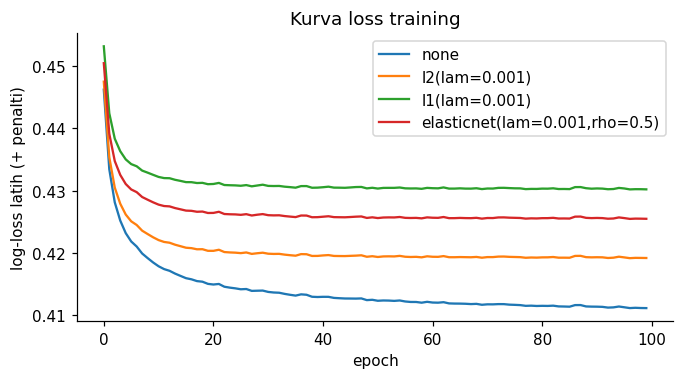

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for name, m in models.items():
    ax.plot(m.loss_history, label=name)
ax.set_xlabel('epoch'); ax.set_ylabel('log-loss latih (+ penalti)')
ax.set_title('Kurva loss training'); ax.legend(); plt.show()

#### Insights

> Pada λ = 10⁻³, keempat varian hampir setara di `val_set` (Macro F1 0,762 sampai 0,764 dan ROC-AUC 0,867 sampai 0,870 pada threshold 0,5). L1 menghasilkan bobot paling jarang (35 dari 80 bobot |w| < 0,01), diikuti Elastic Net (25) dan L2 (3). Karena L1 memakai subgradien, bobot hanya mendekati nol dan tidak tepat nol. Kurva loss sudah melandai sebelum epoch ke-100.

### Tuning Regularisasi (Stratified 5-Fold CV)

Seluruh kandidat `GRID` divalidasi silang pada train (setelah duplikat dibuang). Pada setiap fold, `Preprocessor` di-fit hanya pada bagian latih fold tersebut. Probabilitas out-of-fold dipakai untuk memilih konfigurasi dan threshold dengan Macro F1 tertinggi.

In [22]:
cv = cross_validate(train_clean, y_all)
best_row = cv.sort_values('macro_f1@thr', ascending=False).iloc[0]
best_cfg, threshold = cfg_from_row(best_row), float(best_row['threshold'])
print(f"\nTerbaik: {best_row['config']}  threshold={threshold:.2f}  Macro F1 OOF={best_row['macro_f1@thr']:.4f}")
cv.drop(columns=['penalty', 'lam', 'rho']).set_index('config').round(4)

  none                         macroF1@0.5=0.7692  macroF1@0.45=0.7748  AUC=0.8700  epochs~100  (7.0s)


  l2(lam=0.0001)               macroF1@0.5=0.7689  macroF1@0.45=0.7747  AUC=0.8699  epochs~100  (7.1s)


  l2(lam=0.001)                macroF1@0.5=0.7676  macroF1@0.45=0.7731  AUC=0.8688  epochs~100  (7.1s)


  l2(lam=0.01)                 macroF1@0.5=0.7588  macroF1@0.43=0.7695  AUC=0.8629  epochs~100  (6.8s)


  l1(lam=0.0001)               macroF1@0.5=0.7685  macroF1@0.45=0.7742  AUC=0.8697  epochs~100  (7.1s)


  l1(lam=0.001)                macroF1@0.5=0.7669  macroF1@0.44=0.7721  AUC=0.8667  epochs~100  (6.9s)


  elasticnet(lam=0.0001,rho=0.5) macroF1@0.5=0.7693  macroF1@0.45=0.7749  AUC=0.8697  epochs~97  (7.1s)


  elasticnet(lam=0.001,rho=0.5) macroF1@0.5=0.7666  macroF1@0.46=0.7724  AUC=0.8676  epochs~100  (7.8s)

Terbaik: elasticnet(lam=0.0001,rho=0.5)  threshold=0.45  Macro F1 OOF=0.7749


,macro_f1@0.5,threshold,macro_f1@thr,accuracy@thr,roc_auc,epochs_mean,sec
config,,,,,,,
none,0.7692,0.45,0.7748,0.8032,0.8700,100.0,6.9773
l2(lam=0.0001),0.7689,0.45,0.7747,0.8032,0.8699,100.0,7.0832
l2(lam=0.001),0.7676,0.45,0.7731,0.8023,0.8688,100.0,7.0774
l2(lam=0.01),0.7588,0.43,0.7695,0.7987,0.8629,100.0,6.8482
l1(lam=0.0001),0.7685,0.45,0.7742,0.8028,0.8697,100.0,7.0877
l1(lam=0.001),0.7669,0.44,0.7721,0.8007,0.8667,100.0,6.8713
"elasticnet(lam=0.0001,rho=0.5)",0.7693,0.45,0.7749,0.8034,0.8697,97.0,7.0915
"elasticnet(lam=0.001,rho=0.5)",0.7666,0.46,0.7724,0.8029,0.8676,100.0,7.7706


#### Insights

> Seluruh konfigurasi berada dalam selisih sekitar 0,005 Macro F1. Penalti yang lebih kuat justru menurunkan skor (L2 λ = 10⁻² 0,7695), artinya model dengan 80 fitur untuk sekitar 27 ribu baris tidak overfitting dan regularisasi tidak banyak membantu di data ini. Konfigurasi terbaik adalah Elastic Net λ = 10⁻⁴, ρ = 0,5 dengan threshold 0,45 (Macro F1 OOF 0,7749). Threshold optimal konsisten di sekitar 0,45, di bawah 0,5, sehingga sedikit lebih mudah memprediksi batal menguntungkan Macro F1.

## Model Evaluation

Konfigurasi terbaik dilatih ulang pada `train_set` dan dievaluasi pada `val_set`.

,macro_f1,accuracy,f1_cancel,roc_auc,tn,fp,fn,tp
threshold 0.5,0.7630,0.8001,0.6693,0.8697,3265.0,408.0,684.0,1105.0
threshold 0.45,0.7722,0.8017,0.6901,0.8697,3173.0,500.0,583.0,1206.0


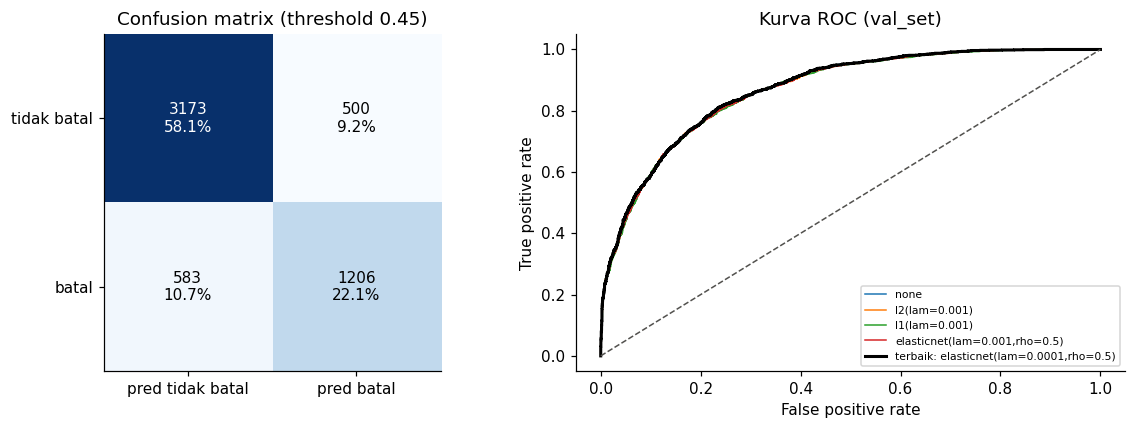

In [23]:
best_model = LogisticRegression(**best_cfg, **TRAIN_KW).fit(X_train, y_train)
p_val = best_model.predict_proba(X_val)
display(pd.DataFrame({'threshold 0.5': report(y_val, p_val, 0.5),
                      f'threshold {threshold:.2f}': report(y_val, p_val, threshold)}).T.round(4))


def roc_points(y, score):
    order = np.argsort(-score)
    tp, fp = np.cumsum(y[order] == 1), np.cumsum(y[order] == 0)
    return np.r_[0, fp / fp[-1]], np.r_[0, tp / tp[-1]]


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
r = report(y_val, p_val, threshold)
cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]])
axes[0].imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, f'{v}\n{v / cm.sum():.1%}', ha='center', va='center',
                 color='white' if v > cm.max() / 2 else 'black')
axes[0].set_xticks([0, 1], ['pred tidak batal', 'pred batal'])
axes[0].set_yticks([0, 1], ['tidak batal', 'batal'])
axes[0].set_title(f'Confusion matrix (threshold {threshold:.2f})')
for name, m in models.items():
    fpr, tpr = roc_points(y_val, m.predict_proba(X_val))
    axes[1].plot(fpr, tpr, linewidth=1, label=name)
fpr, tpr = roc_points(y_val, p_val)
axes[1].plot(fpr, tpr, color='black', linewidth=2, label=f"terbaik: {name_of(best_cfg)}")
axes[1].plot([0, 1], [0, 1], color=CFG.MUTED, linestyle='--', linewidth=1)
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate')
axes[1].set_title('Kurva ROC (val_set)'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

#### Insights

> Pada `val_set`, threshold 0,45 menaikkan Macro F1 dari 0,7630 ke 0,7722. Threshold ini menukar FN (684 → 583) dengan FP (408 → 500). ROC-AUC 0,870 tidak bergantung pada threshold. Kurva ROC keempat varian hampir berimpit, sesuai hasil CV.

## Improvements (Optional)

Threshold keputusan bawaan 0,5 tidak dioptimalkan untuk Macro F1. Kurva berikut memperlihatkan Macro F1 `val_set` terhadap threshold; threshold final tetap dipilih dari prediksi out-of-fold CV, bukan dari `val_set`.

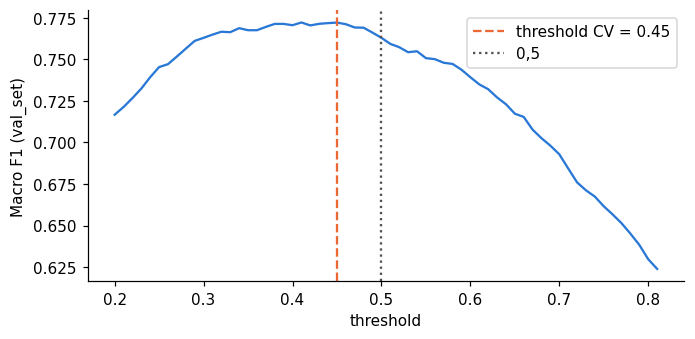

In [24]:
scores = [macro_f1(y_val, (p_val >= t).astype(int)) for t in THRESHOLDS]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(THRESHOLDS, scores, color=CFG.NEG_COLOR)
ax.axvline(threshold, color=CFG.POS_COLOR, linestyle='--', label=f'threshold CV = {threshold:.2f}')
ax.axvline(0.5, color=CFG.MUTED, linestyle=':', label='0,5')
ax.set_xlabel('threshold'); ax.set_ylabel('Macro F1 (val_set)'); ax.legend(); plt.show()

#### Insights

> Macro F1 membentuk dataran yang landai di sekitar threshold 0,42 sampai 0,48, dan threshold hasil CV (0,45) berada di dalamnya, sehingga pilihan ini stabil. Peningkatan berikutnya lebih mungkin datang dari fitur nonlinear (bin lead time dan interaksi kanal × lead time × periode) daripada dari regularisasi atau threshold.

---

# Comparison with scikit-learn <a name="8"></a>

---

`sklearn.linear_model.LogisticRegression` diberi tujuan optimasi yang setara. `lr.py` memakai rata-rata log-loss ditambah $\lambda\,\Omega(w)$, sedangkan scikit-learn memakai $C\sum \text{log-loss} + \Omega(w)$, sehingga $C = 1/(n\lambda)$, dengan `l1_ratio` $= \rho$. Satu konfigurasi terbaik per jenis penalti dari CV dibandingkan pada split yang sama (threshold 0,5).

In [25]:
per_penalty = (cv.assign(p=cv['penalty'].fillna('none'))
               .sort_values('macro_f1@thr', ascending=False).groupby('p').head(1))
cmp = compare_sklearn(train_clean, y_all, [cfg_from_row(r) for _, r in per_penalty.iterrows()])
cmp.set_index(['config', 'impl']).round(4)

  elasticnet(lam=0.0001,rho=0.5) label sama 98.72%  max|w_scratch - w_sklearn|=0.8709  nonzero w: scratch=80 sklearn=70


  none                         label sama 98.44%  max|w_scratch - w_sklearn|=6.2909  nonzero w: scratch=80 sklearn=80


  l2(lam=0.0001)               label sama 98.70%  max|w_scratch - w_sklearn|=0.7331  nonzero w: scratch=80 sklearn=80


  l1(lam=0.0001)               label sama 98.79%  max|w_scratch - w_sklearn|=1.0823  nonzero w: scratch=80 sklearn=67


macro_f1  accuracy  f1_cancel  roc_auc    tn   fp   fn    tp
config                         impl                                                                 
elasticnet(lam=0.0001,rho=0.5) scratch    0.7630    0.8001     0.6693   0.8697  3265  408  684  1105
                               sklearn    0.7652    0.8008     0.6737   0.8712  3251  422  666  1123
none                           scratch    0.7641    0.8010     0.6709   0.8699  3267  406  681  1108
                               sklearn    0.7656    0.8012     0.6743   0.8711  3252  421  665  1124
l2(lam=0.0001)                 scratch    0.7632    0.8003     0.6695   0.8697  3266  407  684  1105
                               sklearn    0.7652    0.8008     0.6737   0.8711  3251  422  666  1123
l1(lam=0.0001)                 scratch    0.7632    0.8001     0.6697   0.8696  3263  410  682  1107
                               sklearn    0.7642    0.8001     0.6723   0.8713  3250  423  669  1120

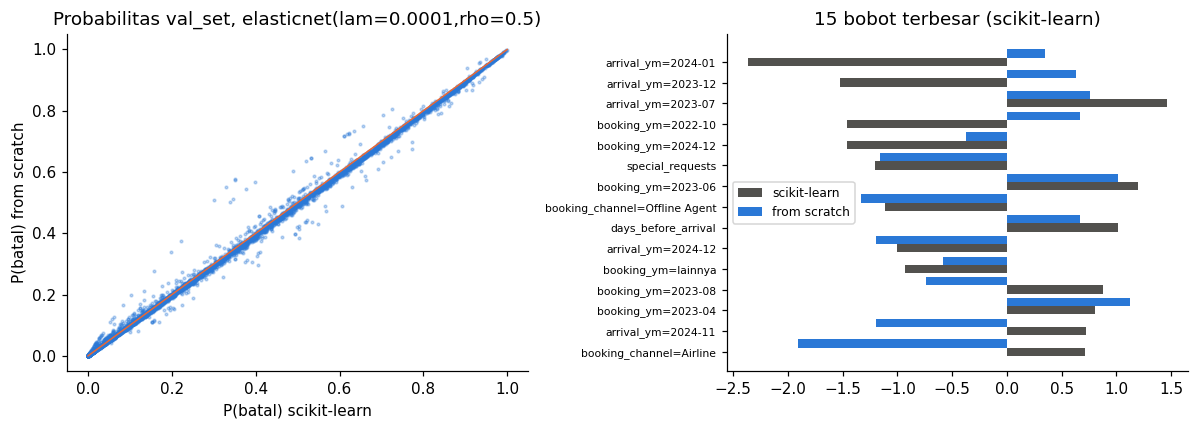

Korelasi probabilitas: 0.9988  |  label sama @0.5: 98.72%


In [26]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sk = sklearn_model(best_cfg, len(y_train)).fit(X_train, y_train)
p_sk = sk.predict_proba(X_val)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(p_sk, p_val, s=3, alpha=0.3, color=CFG.NEG_COLOR)
axes[0].plot([0, 1], [0, 1], color=CFG.POS_COLOR, linewidth=1)
axes[0].set_xlabel('P(batal) scikit-learn'); axes[0].set_ylabel('P(batal) from scratch')
axes[0].set_title(f'Probabilitas val_set, {name_of(best_cfg)}')
idx = np.argsort(-np.abs(sk.coef_.ravel()))[:15]
axes[1].barh(np.array(prep.feature_names_)[idx][::-1], sk.coef_.ravel()[idx][::-1],
             height=0.4, label='scikit-learn', color=CFG.MUTED)
axes[1].barh(np.arange(15)[::-1] + 0.4, best_model.w[idx][::-1],
             height=0.4, label='from scratch', color=CFG.NEG_COLOR)
axes[1].tick_params(axis='y', labelsize=7); axes[1].legend(fontsize=8)
axes[1].set_title('15 bobot terbesar (scikit-learn)')
plt.tight_layout(); plt.show()
print(f'Korelasi probabilitas: {np.corrcoef(p_sk, p_val)[0, 1]:.4f}  |  '
      f'label sama @0.5: {np.mean((p_sk >= 0.5) == (p_val >= 0.5)):.2%}')

#### Insights

> Implementasi from scratch hampir identik dengan scikit-learn: label sama 98,4% sampai 98,8%, korelasi probabilitas 0,9988, dan selisih Macro F1 paling besar 0,0022. scikit-learn sedikit lebih tinggi karena solvernya (lbfgs/saga) konvergen ke optimum, sedangkan SGD from scratch dihentikan setelah 100 epoch. Selisih bobot terbesar ada pada model tanpa penalti (6,29), karena kolom one-hot setiap fitur kategorikal bersama bias saling kolinear, sehingga bobotnya tidak unik walaupun prediksinya sama. scikit-learn L1 menghasilkan bobot tepat nol (67 dari 80 tidak nol), sedangkan subgradien from scratch tidak.

---

# Saving and Loading Models <a name="9"></a>

---

Model disimpan sebagai berkas `.npz` NumPy (bobot, bias, hyperparameter) tanpa pickle, lalu dimuat ulang dan diperiksa bahwa prediksinya identik.

In [27]:
val_model_path = CFG.OUTPUT_DIR / 'lr_model_val.npz'
best_model.save(val_model_path)
restored = LogisticRegression.load(val_model_path)
assert np.array_equal(restored.predict_proba(X_val), p_val)
print(f'{val_model_path} dimuat ulang: prediksi identik ({len(p_val)} baris)')
print({k: getattr(restored, k) for k in ('b', 'lr', 'n_epochs', 'penalty', 'lam', 'rho')})

..\..\output\lr\lr_model_val.npz dimuat ulang: prediksi identik (5462 baris)
{'b': -1.0462556574391797, 'lr': 0.1, 'n_epochs': 100, 'penalty': 'elasticnet', 'lam': 0.0001, 'rho': 0.5}


---

# Kaggle Submission <a name="10"></a>

---

Pipeline dan model final di-fit pada seluruh train (setelah duplikat dibuang), sedangkan test hanya di-`transform`. Konfigurasi dan threshold berasal dari CV. Berkas submisi berisi kolom `id` dan `is_canceled`, dan sama persis dengan keluaran `python src/kaggle/lr_submission.py`.

In [28]:
prep_full = Preprocessor().fit(train_clean)
X_full, X_test = prep_full.transform(train_clean), prep_full.transform(test_df)
final_model = LogisticRegression(**best_cfg, **TRAIN_KW).fit(X_full, y_all)

model_path = CFG.OUTPUT_DIR / 'lr_model.npz'
final_model.save(model_path)
p_test = LogisticRegression.load(model_path).predict_proba(X_test)
assert np.array_equal(p_test, final_model.predict_proba(X_test))

submission = pd.DataFrame({ID_COL: test_df[ID_COL], TARGET: (p_test >= threshold).astype(int)})
assert len(submission) == len(test_df) and submission[ID_COL].is_unique
submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
print(f"Model: {name_of(best_cfg)}  threshold={threshold:.2f}")
print(f"Tersimpan: {CFG.OUTPUT_DIR / 'submission.csv'}  ({len(submission)} baris, "
      f"prediksi batal {submission[TARGET].mean():.1%})")
submission.head()

Model: elasticnet(lam=0.0001,rho=0.5)  threshold=0.45
Tersimpan: ..\..\output\lr\submission.csv  (6844 baris, prediksi batal 30.8%)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

Kesalahan model terbaik pada `val_set` dipecah per kelompok untuk melihat di mana model linear paling lemah.

In [29]:
pred_val = (p_val >= threshold).astype(int)
err = val_set.assign(y=y_val, pred=pred_val,
                     fp=(pred_val == 1) & (y_val == 0), fn=(pred_val == 0) & (y_val == 1),
                     lead_bin=pd.qcut(val_set['days_before_arrival'], 5,
                                      labels=['Q1 (0-11)', 'Q2 (12-39)', 'Q3 (40-81)', 'Q4 (82-151)',
                                              'Q5 (152+)']).astype(object).fillna('kosong'))


def by(col):
    g = err.groupby(col)
    out = pd.DataFrame({'n': g.size(), 'batal': g['y'].mean(), 'pred_batal': g['pred'].mean(),
                        'FP_rate': g['fp'].mean(), 'FN_rate': g['fn'].mean()})
    out['macro_f1'] = [macro_f1(d['y'].to_numpy(), d['pred'].to_numpy()) for _, d in g]
    return out.round(3)


display(by('booking_channel'))
display(by('lead_bin'))

,n,batal,pred_batal,FP_rate,FN_rate,macro_f1
booking_channel,,,,,,
Airline,14,0.429,0.071,0.071,0.429,0.333
Complimentary,62,0.000,0.016,0.016,0.000,0.496
Corporate,303,0.089,0.069,0.030,0.050,0.728
Offline Agent,1569,0.295,0.268,0.077,0.105,0.775
Online Travel Agent,3514,0.368,0.359,0.105,0.113,0.765


,n,batal,pred_batal,FP_rate,FN_rate,macro_f1
lead_bin,,,,,,
Q1 (0-11),1066,0.094,0.027,0.014,0.081,0.583
Q2 (12-39),1035,0.222,0.117,0.032,0.137,0.700
Q3 (40-81),1029,0.231,0.233,0.092,0.090,0.744
Q4 (82-151),1046,0.360,0.402,0.164,0.122,0.696
Q5 (152+),1041,0.736,0.802,0.154,0.087,0.661
kosong,245,0.318,0.245,0.102,0.176,0.657


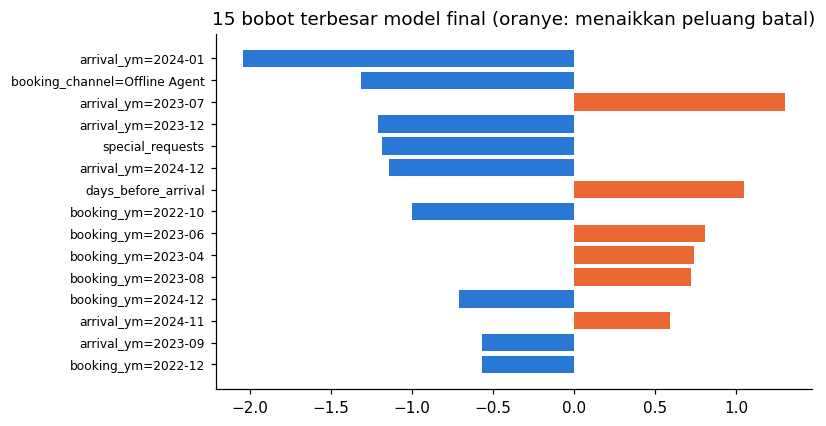

In [30]:
w = pd.Series(final_model.w, index=prep_full.feature_names_)
top = w.reindex(w.abs().sort_values(ascending=False).index)[:15]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index[::-1], top.values[::-1],
        color=[CFG.POS_COLOR if v > 0 else CFG.NEG_COLOR for v in top.values[::-1]])
ax.tick_params(axis='y', labelsize=8)
ax.set_title('15 bobot terbesar model final (oranye: menaikkan peluang batal)'); plt.show()

#### Insights

> Kesalahan terbesar ada pada lead time pendek dan panjang. Untuk lead time 0 sampai 11 hari, tingkat batal aktual 9,4% tetapi model hanya memprediksi 2,7% batal (Macro F1 0,583). Untuk lead time di atas 151 hari, model memprediksi terlalu banyak batal (80,2% terhadap 73,6%, FP rate 15,4%). Kanal Airline hanya 14 baris di `val_set`, sehingga skornya tidak stabil. Pola ini menunjukkan keterbatasan model linear: efek lead time diperlakukan sama di semua kanal dan periode, sehingga interaksi fitur menjadi arah perbaikan utama.

---

## Referensi

- [15] M. L. Khodra, "Logistic Regression: What & Why," YouTube, 2021. https://www.youtube.com/watch?v=QAKZ_pymEzc
- [16] M. L. Khodra, "Logistic Regression: Stochastic Gradient Ascent," YouTube, 2021. https://www.youtube.com/watch?v=O5NSNMQO1yU
- [26] GeeksforGeeks, "Logistic Regression in Machine Learning." https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/
- scikit-learn User Guide, "Logistic regression." https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
- R. Tibshirani, "Regression Shrinkage and Selection via the Lasso," J. R. Stat. Soc. B, 58(1), 1996.
- H. Zou and T. Hastie, "Regularization and Variable Selection via the Elastic Net," J. R. Stat. Soc. B, 67(2), 2005.